# Ariketa 5.3 — Entrenamendua eta erregularizazioa 📉 (EGITEKO)

Sare batek train datuak oso ondo doitzea ez da nahikoa: **generalizatu** egin behar du. Gaur `train` eta `validation` kurbak irakurriko ditugu, gaininskatzea diagnostikatzeko, eta **Dropout + Early Stopping** erabiliko ditugu.


> 🌐 **5072 ML LAB · TRAINING DOCTOR**  
> Underfitting, egokitze ona eta overfitting kurben bidez diagnostikatzeko.  
> **https://rbarrenago.github.io/5072-ml/demos/training-doctor/**


## 📝 Hiru modu

- 🟢 **KOMENTATU** · 🟡 **HUTSUNEAK BETE** (`____`) · 🔴 **KODETU ZEROTIK**


## 0. Prestaketa 🟢 (digituak, S2 bezala)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

digituak = load_digits()
X_train, X_test, y_train, y_test = train_test_split(digituak.data, digituak.target,
                                                    test_size=0.2, random_state=42, stratify=digituak.target)
sc = StandardScaler().fit(X_train)
X_train_s = sc.transform(X_train); X_test_s = sc.transform(X_test)
print('Prest. train/test:', len(X_train), len(X_test))  # 1437 360

Prest. train/test: 1437 360


## 3.1 — Galera, optimizatzailea eta kurbak 🟢

- **Galera:** `sparse_categorical_crossentropy` (klase anizkoitza). Erregresioan `mse` erabil daiteke.
- **Optimizatzailea:** `adam`: gradienteetan oinarritutako optimizatzailea, ikaskuntza-tasa moldakorrekin. Ez da “beti SGD baino hobea”, baina abiapuntu praktiko ona da.
- **Kurbak:** `fit()`-ek `history` itzultzen du → train eta **balidazio** galera alderatzeko.

Sare nahita **handi** bat entrenatuko dugu gaininskatzea ikusgai egiteko.


In [2]:
tf.keras.utils.set_random_seed(42)
handia = keras.Sequential([
    layers.Input((64,)),
    layers.Dense(256, activation='relu'),  # nahita sare handia (256+128 neurona) → overfitting ikusgai egiteko
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])
handia.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
hist = handia.fit(X_train_s, y_train, epochs=120, validation_split=0.2, verbose=0)  # train-aren %20 balidaziorako gorde; history-n epoch bakoitzeko loss/accuracy
print('train acc:', round(hist.history['accuracy'][-1], 3), '| val acc:', round(hist.history['val_accuracy'][-1], 3))  # azken epoch-eko accuracy; tarte handia = gaininskatze-seinalea
best_epoch = int(np.argmin(hist.history['val_loss']) + 1)
print('Balidazio-galera onenaren epoch-a:', best_epoch)


train acc: 1.0 | val acc: 0.969
Balidazio-galera onenaren epoch-a: 18


### a) Kurbak marraztu 🟢

Train-galera eta balidazio-galera. **Banantzen** badira → gaininskatzea.


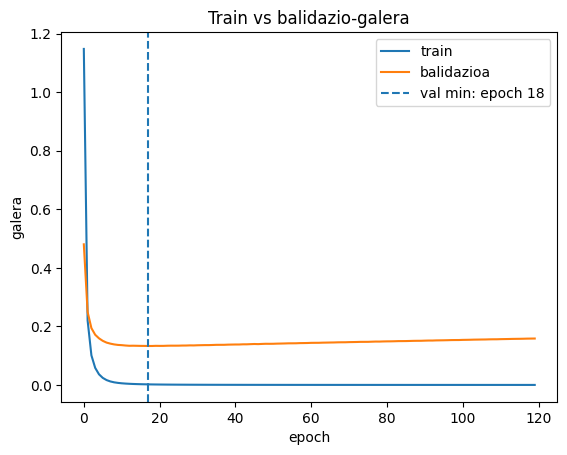

In [3]:
plt.plot(hist.history['loss'], label='train')
plt.plot(hist.history['val_loss'], label='balidazioa')
best_epoch = int(np.argmin(hist.history['val_loss']) + 1)
plt.axvline(best_epoch-1, linestyle='--', label=f'val min: epoch {best_epoch}')
plt.xlabel('epoch'); plt.ylabel('galera'); plt.legend(); plt.title('Train vs balidazio-galera')
plt.show()


## 3.2 — Diagnostikoa

Gaininskatzea ez dugu “train accuracy = 1.0” bakarrik ikusita diagnostikatzen. Seinale sendoagoa da:

- **train loss** jaisten jarraitzea;
- **validation loss** minimo batera iritsi eta gero igotzea;
- train eta validation errendimenduen arteko tartea handitzea.

`best_epoch` exekuzio bakoitzean kalkulatzen dugu; ez dugu epoch zenbaki finko bat buruz ikasten.


## 3.3 — Konponbidea: dropout + early stopping 🟡

- **Dropout:** entrenamenduan neurona batzuk ausaz itzali (ez gehiegi fidatu neurona bakar batez).
- **Early stopping:** balidazio-galerak hobetzeari uzten dionean, gelditu eta eredurik onena berreskuratu.

**Hutsuneak bete:** dropout-tasa eta zein metrika zaindu.


In [4]:
tf.keras.utils.set_random_seed(42)
erregularizatua = keras.Sequential([
    layers.Input((64,)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),  # entrenamenduan neuronen %30 ausaz itzali
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])
erregularizatua.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
# val_loss zaindu: balidazio-galerak 10 epoch-ean hobetzen ez badu → gelditu eta pisu onenak berreskuratu
gelditu = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
hist2 = erregularizatua.fit(X_train_s, y_train, epochs=200, validation_split=0.2, callbacks=[gelditu], verbose=0)
print('Gelditu da epoch:', len(hist2.history['loss']))
print('Test accuracy:', round(erregularizatua.evaluate(X_test_s, y_test, verbose=0)[1], 3))
best_epoch2 = int(np.argmin(hist2.history['val_loss']) + 1)
print('Balidazio-galera onenaren epoch-a:', best_epoch2)


Gelditu da epoch: 19
Test accuracy: 0.975
Balidazio-galera onenaren epoch-a: 9


### a) Kurbak alderatu 🟢

Erregularizatuaren val-galerak **ez** du hain gora egiten.


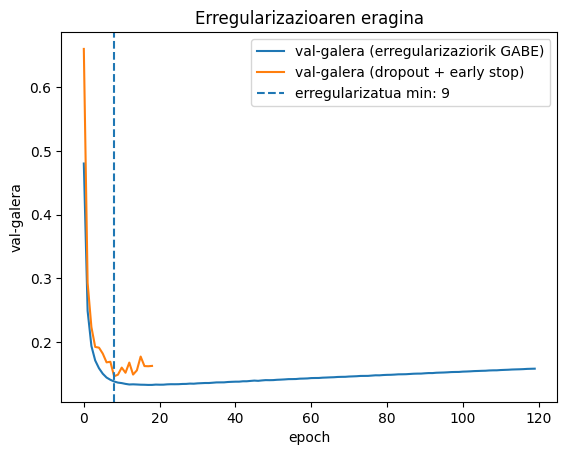

In [5]:
plt.plot(hist.history['val_loss'], label='val-galera (erregularizaziorik GABE)')
plt.plot(hist2.history['val_loss'], label='val-galera (dropout + early stop)')
best_epoch2 = int(np.argmin(hist2.history['val_loss']) + 1)
plt.axvline(best_epoch2-1, linestyle='--', label=f'erregularizatua min: {best_epoch2}')
plt.xlabel('epoch'); plt.ylabel('val-galera'); plt.legend(); plt.title('Erregularizazioaren eragina')
plt.show()


## 🧠 Gako-mezua

- **Train vs validation kurbak** = diagnostiko-tresna.
- **Dropout**: entrenamenduan neurona batzuk ausaz desaktibatzen ditu.
- **Early Stopping**: validation loss hobetzeari uzten dionean entrenamendua gelditzen du eta pisurik onenak berreskuratu ditzake.
- UD4ko Ridge/Lasso-rekin **helburu orokorra partekatzen dute** (overfitting kontrolatu), baina **mekanismo desberdinak** dira.
- Helburua ez da train-ean perfektua izatea, **datu berrietan generalizatzea** baizik.

**Hurrengoan (S4):** irudiak eta CNN.


## Ondorioak

- Gaininskatzea kurben portaeratik diagnostikatzen dugu, ez epoch edo accuracy zenbaki finko batetik.
- `best_epoch` automatikoki kalkulatzea interpretazio zuzena da.
- **Dropout + Early Stopping** generalizazioa hobetzeko bi estrategia dira.
- Test accuracy-a exekuzioaren arabera alda daiteke; test multzoa amaierako ebaluaziorako gordetzen dugu.
- Hurrengoa: **S4 — CNN irudietarako**.
